<a href="https://colab.research.google.com/github/sara-velmont/Proyectos/blob/main/Proyecto_taller.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install feature-engine

#Proyecto: Modelos de aprendizaje estadístico
##Calidad del vino
Este proyecto tiene como objetivo aplicar técnicas de modelos de aprendizaje estadístico para construir un modelo de clasificación capaz de predecir la calidad de un vino. Para ello, se utiliza el conjunto de datos Wine Quality, el cual contiene diversas características físico-químicas de distintos vinos. Con el fin de abordar el problema como una tarea de clasificación binaria, se discretizó la variable de calidad: se consideraron vinos de mala calidad aquellos con una puntuación menor a 6, y de buena calidad aquellos con puntuación igual o superior a 6. A partir de esta transformación, se entrenaron y evaluaron distintos modelos para identificar cuáles ofrecen el mejor desempeño en la predicción de la calidad del vino.

In [ ]:
import kagglehub
import os
# Descarga del Dataset
path = kagglehub.dataset_download("yasserh/wine-quality-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/wine-quality-dataset


Empezando con el preprocesamiento, se transforma la variable de calidad del vino en una variable categórica binaria que permita abordar el problema como una clasificación. Para ello, se crea una nueva columna llamada quality_bin, que asigna la etiqueta '1' a los vinos cuya calidad sea mayor o igual a 6 y '0' a aquellos con calidad menor a 6. Posteriormente, se eliminan las columnas Id y quality, ya que la primera no aporta información relevante para el modelo y la segunda ha sido reemplazada por su versión binarizada.

In [ ]:
# 1. Cargar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Cargar y preparar dataset
csv_path = os.path.join(path, "WineQT.csv")
wine = pd.read_csv(csv_path)

wine['quality_bin'] = wine['quality'].apply(lambda x: 1 if x >= 6 else 0)
wine.drop(['Id', 'quality'], axis=1, inplace=True)



In [ ]:
wine['quality_bin'].dtype

dtype('int64')

Después de transformar la variable de calidad en una clasificación binaria y eliminar una columna innecesaria, se calcula la distribución de clases en la nueva variable quality_bin para evaluar el balance del conjunto de datos. Esto se realiza generando una tabla de frecuencias absolutas de las etiquetas "1" para buena calidad y '0' para baja, y luego convirtiéndola en proporciones relativas para conocer el porcentaje que representa cada clase respecto al total de observaciones. Esta información es esencial para identificar si existe un desbalance que pueda afectar el desempeño del modelo de clasificación.

In [ ]:
# 3. Proporciones de clases
# Calcular frecuencias absolutas
frecuencias = wine['quality_bin'].value_counts()

# Calcular proporciones relativas
proporciones = wine['quality_bin'].value_counts(normalize=True)

print("Proporciones de calidad (binarizada):")
print(proporciones)


Proporciones de calidad (binarizada):
quality_bin
1    0.543307
0    0.456693
Name: proportion, dtype: float64


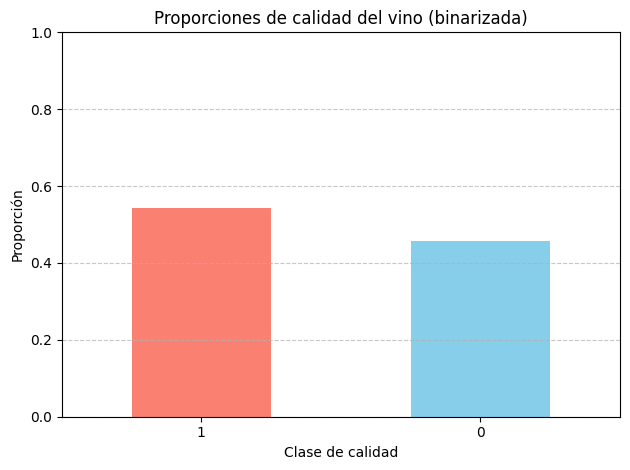

In [ ]:
# Gráfico de barras
proporciones.plot(kind='bar', color=['salmon', 'skyblue'])

# Personalización del gráfico
plt.title('Proporciones de calidad del vino (binarizada)')
plt.xlabel('Clase de calidad')
plt.ylabel('Proporción')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Una vez definida la variable de respuesta y evaluado el balance entre clases, se analizan las correlaciones entre las variables numéricas del conjunto de datos con el fin de identificar relaciones lineales o monótonas que puedan influir en la selección de características o en la interpretación del modelo. Para ello, se excluye la variable de respuesta quality_bin y se calculan dos matrices de correlación: una utilizando el coeficiente de Pearson, que mide la fuerza y dirección de relaciones lineales entre variables, y otra con el coeficiente de Spearman, que evalúa relaciones monótonas basadas en rangos. Ambas matrices se visualizan mediante mapas de calor, lo que permite detectar rápidamente patrones de asociación fuerte o débil entre las variables predictoras. Esta información es útil tanto para la reducción de dimensiones como para entender posibles redundancias en los datos.

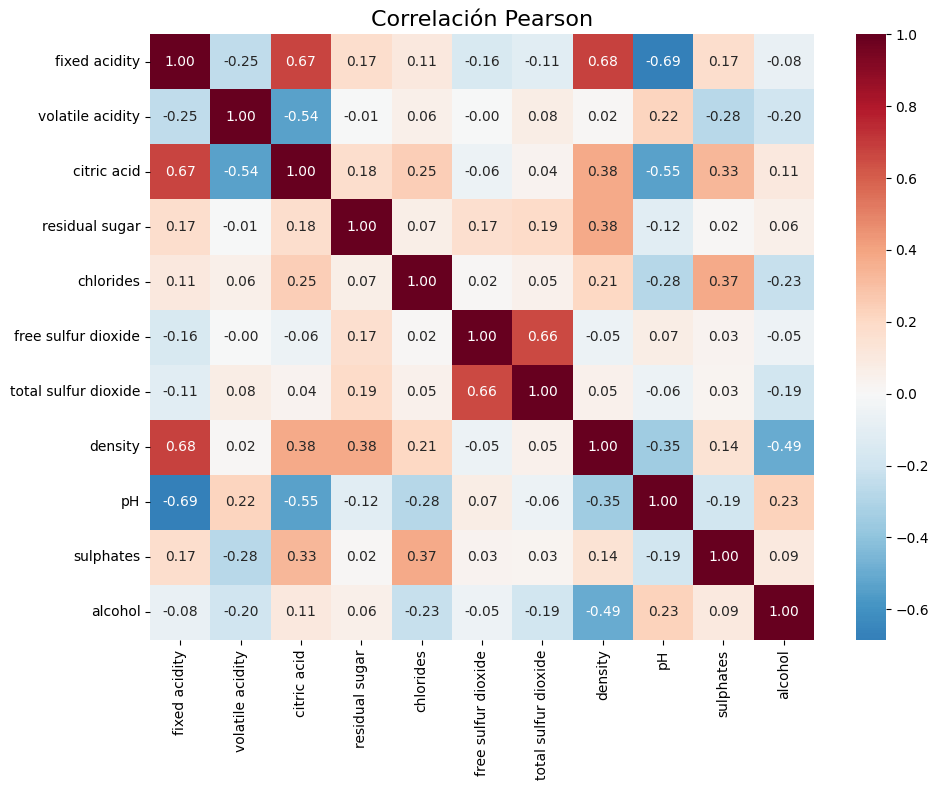

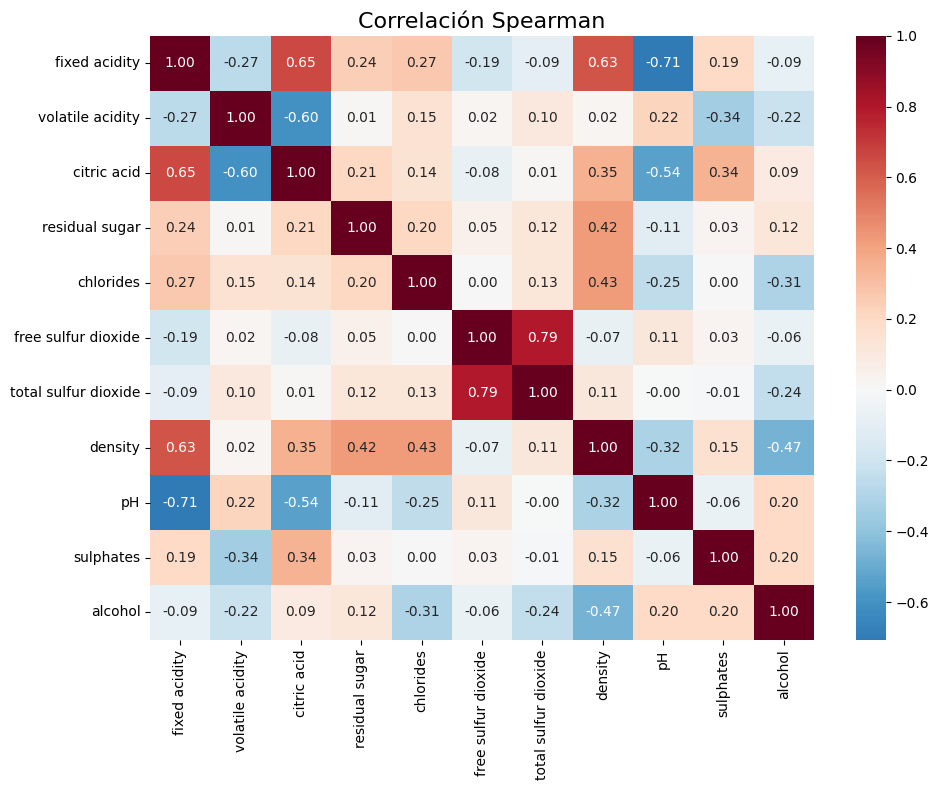

In [ ]:
from scipy.stats import spearmanr

# 4. Correlaciones entre variables numéricas
# Seleccionar sólo variables numéricas (excluyendo quality_bin)
wine_numericas = wine.drop(columns=['quality_bin'])

# Calcular la matriz de correlación de Pearson
cor_pearson = wine_numericas.corr(method='pearson')

# Calcular la matriz de correlación de Spearman
cor_spearman = wine_numericas.corr(method='spearman')

# Visualización: Pearson
plt.figure(figsize=(10, 8))
sns.heatmap(cor_pearson, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación Pearson", fontsize=16)
plt.tight_layout()
plt.show()

# Visualización: Spearman
plt.figure(figsize=(10, 8))
sns.heatmap(cor_spearman, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación Spearman", fontsize=16)
plt.tight_layout()
plt.show()


Después de calcular la matriz de correlación de Spearman, se identifican pares de variables numéricas que presentan una correlación fuerte, es decir, con un coeficiente absoluto mayor a 0.9. Este análisis permite detectar relaciones casi lineales o altamente redundantes entre variables, lo cual es importante para evitar colinealidad en modelos sensibles a dicha condición y para reducir la complejidad del modelo eliminando características duplicadas en términos de información. Si se detectan estas correlaciones, se imprimen los pares de variables junto con el valor exacto del coeficiente de correlación. En caso contrario, se indica que no existen correlaciones fuertes.

In [ ]:
# 5. Correlaciones fuertes
# Umbral de correlación fuerte
umbral = 0.9

# Matriz booleana donde se cumple la condición |corr| > 0.9 (excepto la diagonal)
mask_altas = (np.abs(cor_spearman) > umbral) & (cor_spearman != 1.0)

# Obtener pares de índices donde se cumple la condición
pares_altas = np.argwhere(mask_altas.values)

# Evitar duplicados como (A, B) y (B, A)
pares_filtrados = []
for i, j in pares_altas:
    if i < j:  # evitar repeticiones
        v1 = cor_spearman.index[i]
        v2 = cor_spearman.columns[j]
        val = cor_spearman.iloc[i, j]
        pares_filtrados.append((v1, v2, val))

if pares_filtrados:
    print("\nCorrelaciones fuertes (>|0.9|):")
    for v1, v2, val in pares_filtrados:
        print(f"- {v1} vs {v2}: {val:.2f}")
else:
    print("\nNo hay correlaciones fuertes.")



No hay correlaciones fuertes.


Además del análisis basado en la correlación de Spearman, se realiza un estudio complementario utilizando la matriz de correlación de Pearson con el objetivo de identificar relaciones lineales fuertes entre pares de variables numéricas. Este tipo de correlación es especialmente relevante en modelos que asumen linealidad o que pueden verse afectados por la colinealidad, como la regresión logística o la regresión lineal. Se consideran correlaciones fuertes aquellas cuyo coeficiente absoluto supera el umbral de 0.9, y se reportan únicamente los pares no redundantes. Detectar estas asociaciones permite tomar decisiones informadas sobre la posible eliminación de variables redundantes y contribuye a simplificar el modelo sin pérdida significativa de información.

In [ ]:
# Umbral de correlación fuerte
umbral = 0.9

# Matriz booleana para Pearson
mask_altas_pearson = (np.abs(cor_pearson) > umbral) & (cor_pearson != 1.0)

pares_altas_pearson = np.argwhere(mask_altas_pearson.values)
pares_filtrados_pearson = []
for i, j in pares_altas_pearson:
    if i < j:
        v1 = cor_pearson.index[i]
        v2 = cor_pearson.columns[j]
        val = cor_pearson.iloc[i, j]
        pares_filtrados_pearson.append((v1, v2, val))

if pares_filtrados_pearson:
    print("\nCorrelaciones fuertes de Pearson (>|0.9|):")
    for v1, v2, val in pares_filtrados_pearson:
        print(f"- {v1} vs {v2}: {val:.2f}")
else:
    print("\nNo hay correlaciones fuertes de Pearson.")



No hay correlaciones fuertes de Pearson.


Dado que no se detectaron correlaciones fuertes entre las variables numéricas del conjunto de datos, ni utilizando el coeficiente de Pearson ni el de Spearman, se puede concluir que no existen relaciones lineales ni monótonas excesivamente fuertes entre las variables predictoras. Esto sugiere que no hay redundancia evidente en la información contenida en las variables, lo cual es favorable para el modelado, ya que reduce el riesgo de colinealidad y permite conservar todas las variables numéricas originales sin necesidad de eliminar alguna por dependencia estadística. Además, esta independencia relativa puede favorecer el desempeño de modelos que se benefician de atributos informativos diversos.

A continuación, se verificó la presencia de datos faltantes en el conjunto de datos y se confirmó que no existen valores ausentes. Esto indica que no es necesario aplicar técnicas de imputación o eliminación de registros, por lo que se puede continuar directamente con el modelado.

In [ ]:
#6 Verificar cantidad total de datos faltantes en el DataFrame
print("\nDatos faltantes:", wine.isna().sum().sum())


Datos faltantes: 0


Se utilizó el algoritmo Local Outlier Factor (LOF) para detectar posibles observaciones atípicas dentro del conjunto de variables numéricas, estableciendo como umbral el percentil 95 de las puntuaciones obtenidas. Posteriormente, se visualizó la distribución de los datos en el espacio reducido por Análisis de Componentes Principales (PCA), lo que permitió observar que los outliers detectados representan un porcentaje reducido y no alteran significativamente la estructura general del conjunto. Por tanto, se decidió conservar estas observaciones para el análisis posterior. Además de que los modelos utilizados son robustos ante este tipo de datos atípicos.


Outliers (top 5%): 58


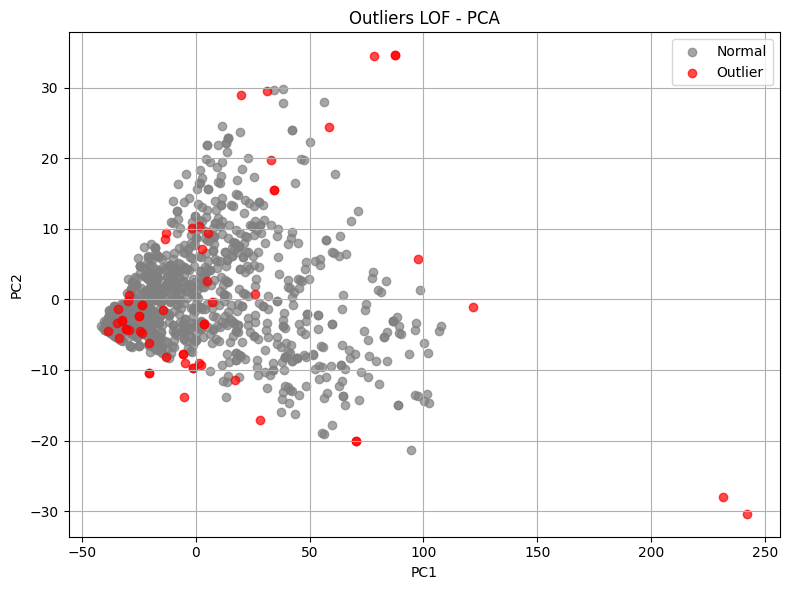

In [ ]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

# 7. Detección de outliers con LOF
# Aplicar LOF (Local Outlier Factor)
lof = LocalOutlierFactor(n_neighbors=10)
lof_scores = -lof.fit_predict(wine_numericas)
lof_values = -lof.negative_outlier_factor_

# Definir umbral como percentil 95
umbral = np.quantile(lof_values, 0.95)
outliers = lof_values > umbral

print("Outliers (top 5%):", np.sum(outliers))

# PCA para visualización
pca = PCA(n_components=2)
pca_result = pca.fit_transform(wine_numericas)
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"])
pca_df["outlier"] = np.where(outliers, "Outlier", "Normal")

plt.figure(figsize=(8, 6))
colors = {"Normal": "grey", "Outlier": "red"}
for clase in ["Normal", "Outlier"]:
    subset = pca_df[pca_df["outlier"] == clase]
    plt.scatter(subset["PC1"], subset["PC2"],
                label=clase, c=colors[clase], alpha=0.7)
plt.title("Outliers LOF - PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


A continuación, se realiza un escalamiento en las variables predictoras. Por otro lado para garantizar una evaluación objetiva del modelo, se dividió el conjunto de datos en subconjuntos de entrenamiento (80%) y prueba (20%) utilizando un muestreo estratificado con base en la variable de respuesta quality_bin. Esta estrategia asegura que la proporción de clases se mantenga constante en ambos subconjuntos, lo que permite un entrenamiento representativo y una evaluación fiable del desempeño del modelo en datos no vistos. Además, se estableció una semilla aleatoria para asegurar la reproducibilidad del proceso.











In [ ]:
# 8. División en conjunto de entrenamiento y prueba
from sklearn.model_selection import train_test_split

#Para escalar las variables predictoras
from sklearn.preprocessing import StandardScaler
from feature_engine.wrappers import SklearnTransformerWrapper

# Se hace la envoltura de StandardScaler dentro
# de SklearnTransformerWrapper
scaler = SklearnTransformerWrapper(transformer = StandardScaler())

X_wine = wine.drop(columns=['quality_bin'])
y_wine = wine['quality_bin']

# Ajuste wrapper + StandardScaler
scaler.fit(X_wine)

# Transformación de los datos
X_transf = scaler.transform(X_wine)

# División en 80% entrenamiento y 20% prueba, estratificada según quality_bin
X_train, X_test, y_train, y_test = train_test_split(
    X_transf, y_wine,
    test_size=0.2,
    stratify=wine['quality_bin'],
    random_state=123
)


Se implementó un modelo de regresión logística con regularización Ridge (penalización L2) para clasificar la calidad del vino, utilizando validación cruzada estratificada de 5 particiones para garantizar una evaluación robusta y evitar sobreajuste. El hiperparámetro de regularización lambda se optimizó mediante una búsqueda en rejilla dentro de un rango específico, utilizando el área bajo la curva ROC (AUC ROC) como métrica principal para maximizar la capacidad discriminativa del modelo entre clases. Esta metodología permite ajustar el nivel de penalización para mejorar el rendimiento predictivo y la generalización del modelo en datos no vistos.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, make_scorer

# Definir validación cruzada estratificada de 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# Definir la métrica para optimizar: AUC ROC
scorer = 'roc_auc'

# Preparar hiperparámetros para Ridge (penalización L2: alpha=0)
# En scikit-learn, el parámetro de regularización es C = 1/lambda
lambdas = np.linspace(0.001, 0.1, 10)
param_grid = {'C': 1 / lambdas}

# Crear el modelo de regresión logística con penalización L2 (Ridge)
logreg = LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000)

# GridSearch con validación cruzada para optimizar lambda
grid_search = GridSearchCV(
    estimator=logreg,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    refit=True,
    verbose=0,
    error_score='raise'
)

# Ajustar el modelo con datos de entrenamiento escalados
grid_search.fit(X_train, y_train)

# Mejor hiperparámetro y mejor score
print("Mejor lambda (regularización):", 1 / grid_search.best_params_['C'])
print("Mejor AUC ROC en CV:", grid_search.best_score_)


Mejor lambda (regularización): 0.067
Mejor AUC ROC en CV: 0.8191048523096717


Se entrenó un modelo de regresión logística con regularización Lasso (penalización L1) para la predicción de la calidad del vino, empleando validación cruzada estratificada de 5 particiones y optimización del parámetro de regularización lambda a través de una búsqueda en rejilla. Al igual que en el caso de Ridge, se utilizó el área bajo la curva ROC (AUC ROC) como métrica principal para seleccionar el mejor modelo. La penalización L1 tiene la ventaja adicional de realizar una selección automática de variables, ya que tiende a reducir a cero los coeficientes de aquellas que aportan poca información, lo que permite simplificar el modelo y mejorar su interpretabilidad sin sacrificar desempeño predictivo.

In [ ]:
# Modelo Lasso = regresión logística con penalización L1
logreg_lasso = LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000)

# Búsqueda de hiperparámetros con validación cruzada
grid_search_lasso = GridSearchCV(
    estimator=logreg_lasso,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    refit=True,
    verbose=0
)

# Entrenamiento
grid_search_lasso.fit(X_train, y_train)

# Resultados
print("Mejor lambda (Lasso):", 1 / grid_search_lasso.best_params_['C'])
print("Mejor AUC ROC en CV:", grid_search_lasso.best_score_)

Mejor lambda (Lasso): 0.023000000000000003
Mejor AUC ROC en CV: 0.8190807559241294


Text(0.5, 1.0, 'Comparación de coeficientes: Lasso vs Ridge')

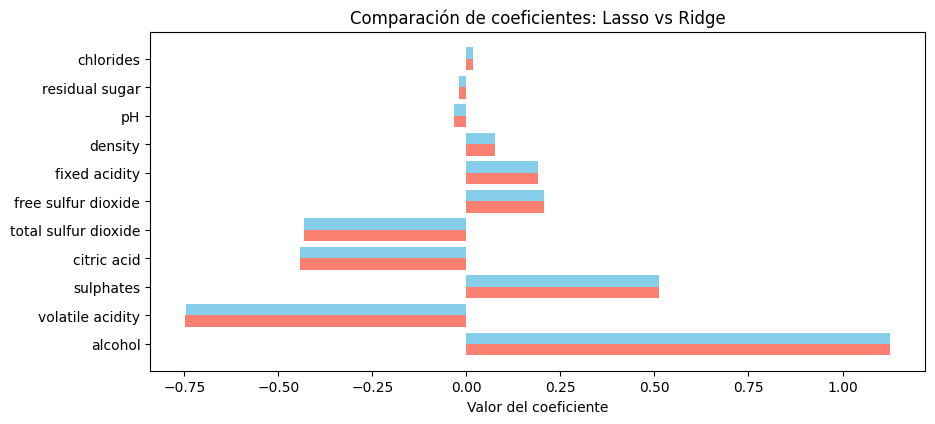

In [ ]:
# Obtener nombres de las variables
features = X_train.columns

# Obtener los coeficientes del mejor modelo Lasso
lasso_model = grid_search_lasso.best_estimator_
coef_lasso = lasso_model.coef_.flatten()

# Obtener los coeficientes del mejor modelo Ridge
ridge_model = grid_search.best_estimator_
coef_ridge = ridge_model.coef_.flatten()

# Crear un DataFrame con ambos resultados
coef_df = pd.DataFrame({
    'Variable': features,
    'Lasso': coef_lasso,
    'Ridge': coef_ridge
})

# Ordenar por el valor absoluto del coeficiente de Lasso o Ridge (para visualización más clara)
coef_df['Importancia'] = np.abs(coef_df['Lasso']) + np.abs(coef_df['Ridge'])
coef_df = coef_df.sort_values(by='Importancia', ascending=False)

# Crear la gráfica
plt.figure(figsize=(10, len(features) * 0.4))

# Posiciones para las barras
y_pos = np.arange(len(coef_df))

# Ancho de separación entre Lasso y Ridge
bar_width = 0.4

# Barras Lasso
plt.barh(y_pos - bar_width / 2, coef_df['Lasso'], bar_width, label='Lasso (L1)', color='salmon')

# Barras Ridge
plt.barh(y_pos + bar_width / 2, coef_df['Ridge'], bar_width, label='Ridge (L2)', color='skyblue')

# Etiquetas y leyenda
plt.yticks(y_pos, coef_df['Variable'])
plt.xlabel("Valor del coeficiente")
plt.title("Comparación de coeficientes: Lasso vs Ridge")


Según los coeficientes obtenidos en los modelos Lasso y Ridge y asumiendo que los valores negativos indican contribución a la mala calidad y los positivos a la buena calidad, se observa que las variables que más se asocian con vinos de menor calidad son density, volatile acidity y sulphates, ya que presentan coeficientes negativos de gran magnitud. Por otro lado, las variables que más contribuyen a predecir vinos de buena calidad son citric acid y alcohol, al mostrar coeficientes positivos elevados en ambos modelos. Esta interpretación es consistente en Lasso y Ridge, lo que refuerza la confianza en que estas características químicas desempeñan un papel importante en la diferenciación de la calidad del vino.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Definir validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# Definir el modelo
tree = DecisionTreeClassifier(random_state=123)

# Definir el grid de hiperparámetros (por ejemplo: profundidad)
param_grid = {
    'max_depth': list(range(1, 11))  # equivalente a tuneLength = 10
}

# Definir el scorer con métrica AUC
scorer = make_scorer(roc_auc_score)

# GridSearch con validación cruzada
grid_search_tree = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    refit=True
)

# Entrenar el modelo
grid_search_tree.fit(X_train, y_train)



GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=123, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=123),
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]},
             scoring=make_scorer(roc_auc_score, response_method='predict'))

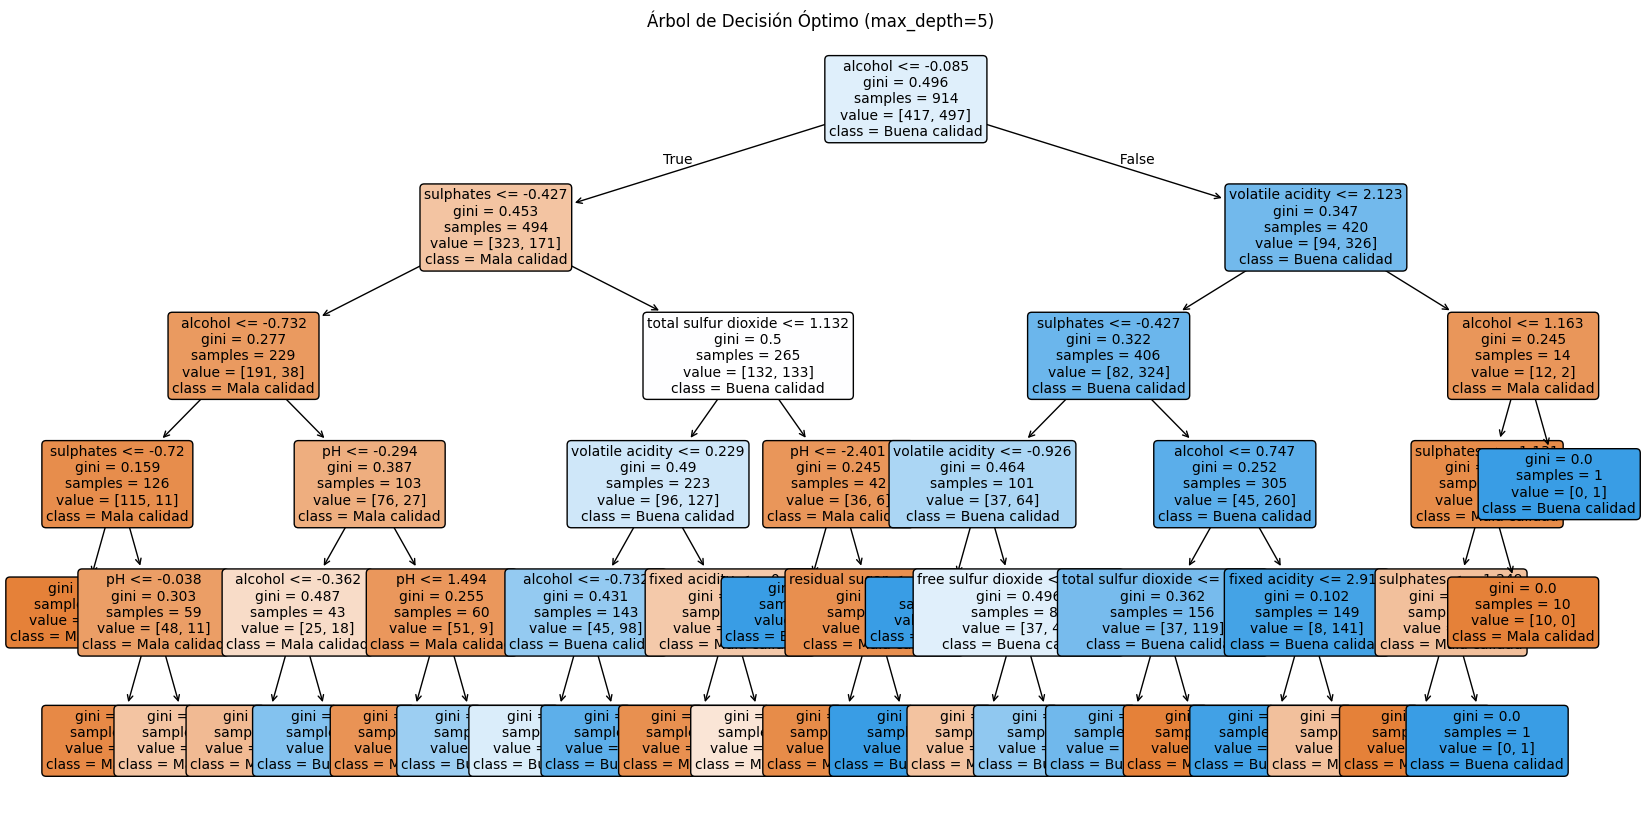

In [ ]:
from sklearn.tree import plot_tree

# Mejor modelo encontrado
best_tree = grid_search_tree.best_estimator_

# Visualización
plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=X_train.columns,
    class_names=["Mala calidad", "Buena calidad"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión Óptimo (max_depth=5)")
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# Métrica AUC
scorer = make_scorer(roc_auc_score)

# Definir el modelo base
rf = RandomForestClassifier(random_state=123)

# Definir hiperparámetros para tuneo básico
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250],  # número de árboles
    'max_depth': [None, 5, 10, 15, 20]         # profundidad máxima
}

# Búsqueda en grilla con validación cruzada
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    refit=True,
    verbose=0
)

# Entrenar el modelo
grid_search_rf.fit(X_train, y_train)

# Resultados
print("Mejores hiperparámetros:", grid_search_rf.best_params_)
print("Mejor AUC ROC:", grid_search_rf.best_score_)


Mejores hiperparámetros: {'max_depth': 15, 'n_estimators': 150}
Mejor AUC ROC: 0.7740350319025018


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# Métrica AUC como función de evaluación
scorer = make_scorer(roc_auc_score)

# Modelo base
gb = GradientBoostingClassifier(random_state=123)

# Hiperparámetros para búsqueda en rejilla
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# GridSearchCV
grid_search_gb = GridSearchCV(
    estimator=gb,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    refit=True,
    verbose=0
)

# Entrenamiento del modelo
grid_search_gb.fit(X_train, y_train)

# Resultados
print("Mejores hiperparámetros:", grid_search_gb.best_params_)
print("Mejor AUC ROC:", grid_search_gb.best_score_)


Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
Mejor AUC ROC: 0.7706583215980806


Se realizó una comparación del desempeño de los modelos entrenados: Ridge, Lasso, árbol de decisión, Random Forest y grdiente potenciado aplicando validación cruzada estratificada de cinco particiones y utilizando el AUC ROC como métrica de evaluación. Para ello, se calcularon los puntajes de AUC obtenidos en cada partición de validación y se representaron mediante un gráfico de caja, lo cual permite visualizar tanto la tendencia central como la dispersión del rendimiento de cada modelo. Este análisis comparativo se ha hecho para seleccionar el modelo más robusto y estable, basado en su capacidad para claasificar correctamente vinos de buena y mala calidad.

          Ridge     Lasso     Árbol        RF        GB
count  5.000000  5.000000  5.000000  5.000000  5.000000
mean   0.827392  0.827440  0.793731  0.854500  0.844096
std    0.010850  0.010784  0.028984  0.014982  0.013286
min    0.815422  0.815663  0.764096  0.830181  0.824940
25%    0.822320  0.822320  0.769928  0.849928  0.835585
50%    0.824435  0.824435  0.794192  0.862289  0.850602
75%    0.830568  0.830568  0.804217  0.864001  0.854257
max    0.844217  0.844217  0.836219  0.866101  0.855099


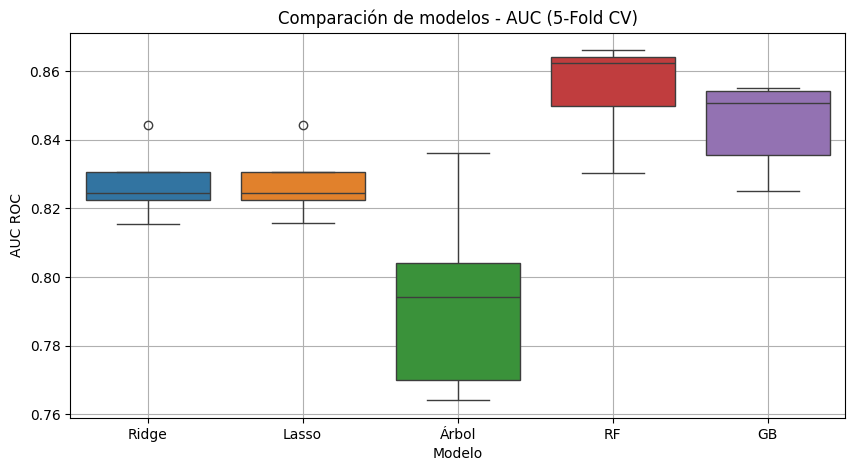

In [ ]:
from sklearn.model_selection import cross_val_score

# Lista de modelos entrenados (ya optimizados con GridSearchCV)
modelos = {
    'Ridge': grid_search.best_estimator_,
    'Lasso': grid_search_lasso.best_estimator_,
    'Árbol': grid_search_tree.best_estimator_,
    'RF': grid_search_rf.best_estimator_,
    'GB': grid_search_gb.best_estimator_
}

# Validación cruzada para comparar AUCs
resultados = {}
for nombre, modelo in modelos.items():
    scores = cross_val_score(
        modelo,
        X_train,
        y_train,
        scoring='roc_auc',
        cv=5
    )
    resultados[nombre] = scores

# Convertir a DataFrame para visualización
df_resultados = pd.DataFrame(resultados)

# Resumen estadístico
print(df_resultados.describe())

# Boxplot comparativo de AUCs
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_resultados)
plt.title("Comparación de modelos - AUC (5-Fold CV)")
plt.ylabel("AUC ROC")
plt.xlabel("Modelo")
plt.grid(True)
plt.show()


Se evaluó el desempeño de los modelos entrenados sobre un conjunto de prueba independiente, calculando las métricas AUC, exactitud, precisión y recall. Esta evaluación permite comprobar qué tan bien generaliza cada modelo a nuevos datos no vistos durante el entrenamiento. El AUC refleja la capacidad del modelo para discriminar entre vinos de buena y mala calidad, mientras que la precisión y el recall aportan información sobre la calidad de las predicciones positivas. Este análisis complementa la validación cruzada al ofrecer una medida más realista del rendimiento esperable del modelo en la práctica.

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, confusion_matrix

# Diccionario de modelos ajustados
modelos = {
    'Ridge': grid_search.best_estimator_,
    'Lasso': grid_search_lasso.best_estimator_,
    'Árbol': grid_search_tree.best_estimator_,
    'RF': grid_search_rf.best_estimator_,
    'GB': grid_search_gb.best_estimator_
}

print("\n--- Evaluación en conjunto de prueba ---\n")

for nombre, modelo in modelos.items():
    # Predicción de probabilidades y clases
    y_proba = modelo.predict_proba(X_test)[:, 1]
    y_pred = (y_proba > 0.5).astype(int)

    # Cálculo de métricas
    auc = roc_auc_score(y_test, y_proba)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)

    # Mostrar resultados
    print(f"\nModelo: {nombre}")
    print(f"  AUC       : {auc:.3f}")
    print(f"  Accuracy  : {acc:.3f}")
    print(f"  Precision : {prec:.3f}")
    print(f"  Recall    : {rec:.3f}")



--- Evaluación en conjunto de prueba ---


Modelo: Ridge
  AUC       : 0.806
  Accuracy  : 0.729
  Precision : 0.767
  Recall    : 0.718

Modelo: Lasso
  AUC       : 0.806
  Accuracy  : 0.729
  Precision : 0.767
  Recall    : 0.718

Modelo: Árbol
  AUC       : 0.818
  Accuracy  : 0.751
  Precision : 0.768
  Recall    : 0.774

Modelo: RF
  AUC       : 0.859
  Accuracy  : 0.751
  Precision : 0.764
  Recall    : 0.782

Modelo: GB
  AUC       : 0.853
  Accuracy  : 0.755
  Precision : 0.766
  Recall    : 0.790


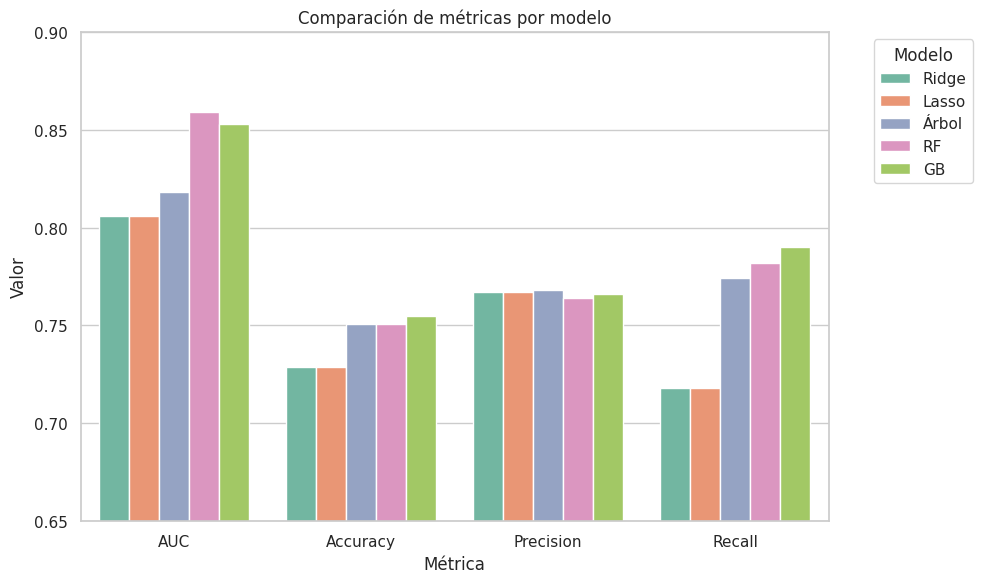

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Datos
data = {
    'Modelo': ['Ridge', 'Lasso', 'Árbol', 'RF', 'GB'],
    'AUC': [0.806, 0.806, 0.818, 0.859, 0.853],
    'Accuracy': [0.729, 0.729, 0.751, 0.751, 0.755],
    'Precision': [0.767, 0.767, 0.768, 0.764, 0.766],
    'Recall': [0.718, 0.718, 0.774, 0.782, 0.790]
}

# Convertir a DataFrame
df = pd.DataFrame(data)

# Convertir a formato largo (long format) para usar con seaborn
df_long = pd.melt(df, id_vars='Modelo', var_name='Métrica', value_name='Valor')

# Estilo bonito
sns.set(style='whitegrid')
plt.figure(figsize=(10, 6))

# Gráfico
sns.barplot(data=df_long, x='Métrica', y='Valor', hue='Modelo', palette='Set2')

# Personalización
plt.title('Comparación de métricas por modelo')
plt.ylim(0.65, 0.90)
plt.legend(title='Modelo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()


Se graficaron las curvas ROC de los modelos entrenados para visualizar su capacidad de discriminación en el conjunto de prueba. La curva ROC representa la relación entre la tasa de verdaderos positivos (TPR) y la tasa de falsos positivos (FPR) a diferentes umbrales de clasificación. Cuanto más se acerque la curva al vértice superior izquierdo del gráfico, mejor será el desempeño del modelo. Esta visualización sirve para comparar los modelos de clasificación binaria.

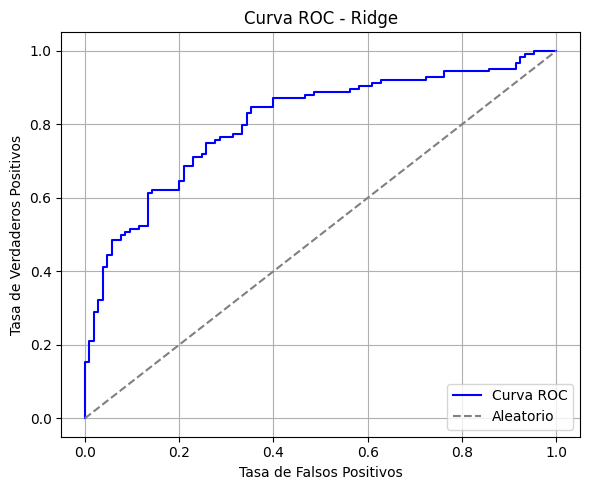

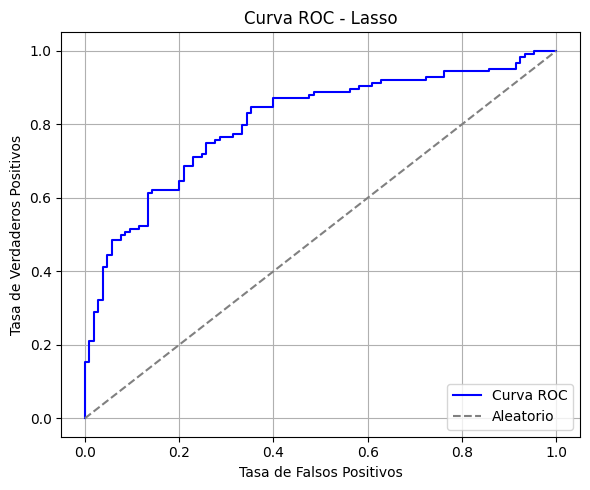

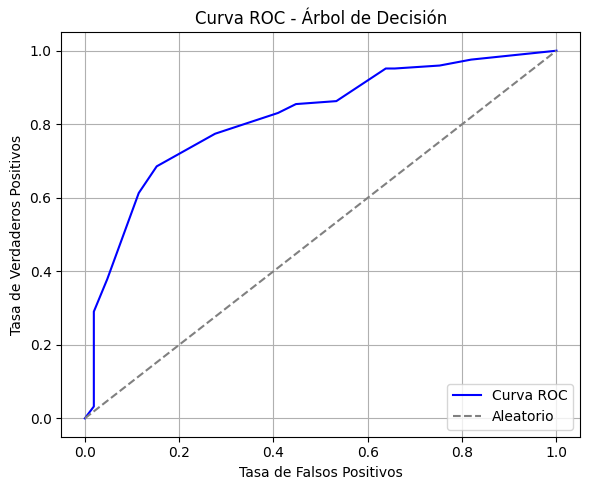

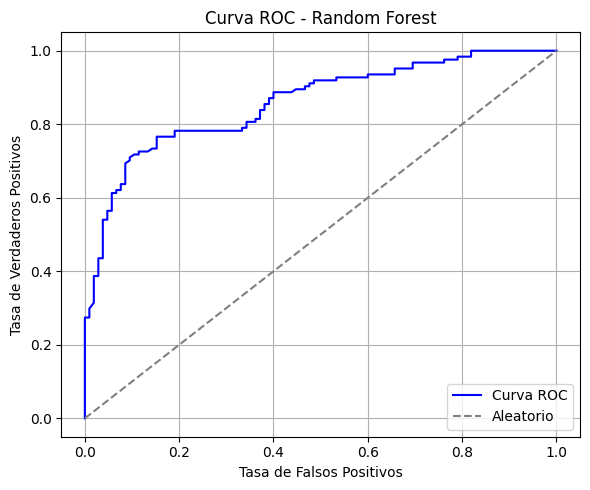

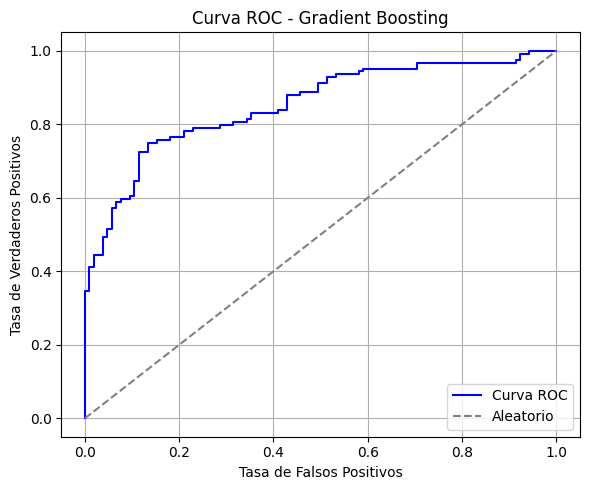


Análisis completado.



In [ ]:
from sklearn.metrics import roc_curve

# Función para graficar curva ROC
def plot_roc(modelo, X_test, y_test, nombre_modelo):
    y_proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='blue', label='Curva ROC')
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Aleatorio')
    plt.xlabel("Tasa de Falsos Positivos")
    plt.ylabel("Tasa de Verdaderos Positivos")
    plt.title(f"Curva ROC - {nombre_modelo}")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Aplicar a todos los modelos
plot_roc(grid_search.best_estimator_, X_test, y_test, "Ridge")
plot_roc(grid_search_lasso.best_estimator_, X_test, y_test, "Lasso")
plot_roc(grid_search_tree.best_estimator_, X_test, y_test, "Árbol de Decisión")
plot_roc(grid_search_rf.best_estimator_, X_test, y_test, "Random Forest")
plot_roc(grid_search_gb.best_estimator_, X_test, y_test, "Gradient Boosting")

print("\nAnálisis completado.\n")
